# Student 1 Individual Notebook

Natalie Schweickert

Student 1: A penalized (Ridge, Lasso or ElasticNet) linear model (Linear Regression or Logistic Regression, as appropriate) AND a Support Vector Machine.

**Objective**
The objective of this analysis is to develop and evaluate classification models that predict whether an individual will experience serious delinquency within two years (dlq_2yrs).

Because the target variable is binary, with values of 0 and 1, classification algorithms are appropriate for this task. This analysis focuses on two assigned modeling approaches:

Penalized Logistic Regression: Evaluates the effectiveness of L1 and L2 regularization when predicting serious delinquency.

Support Vector Machine (SVM): Uses a nonlinear kernel to identify potentially complex relationships between the predictors and the target variable.

A baseline Logistic Regression model is also included as a reference point for comparison.

The models are evaluated using stratified cross-validation, hyperparameter optimization, and a separate holdout test set. Multiple classification metrics are used to compare predictive performance and understand the tradeoffs between precision, recall, and overall model discrimination.*

## Model Training and Optimization

**Data Preparation**
The training dataset is loaded and separated into predictor variables (X) and the target variable (y). The target variable, dlq_2yrs, indicates whether an individual experienced serious delinquency within two years.

All remaining columns are used as predictor variables. The dataset is divided into training and holdout test sets using an 80/20 split. Stratified sampling is applied to preserve the proportion of each target class in both sets.

A random state of 1234 is used to support reproducibility. The holdout test set is reserved for final model evaluation and is not used during hyperparameter optimization.

In [1]:
# import
import pandas as pd

# read training dataset
df = pd.read_csv("../../Data/training.csv")
df.head()

,rev_util,age,late_30_59,debt_ratio,monthly_inc,open_credit,late_90,real_estate,late_60_89,dependents,dlq_2yrs
0,0.793106,35.0,1.0,0.098301,3000.0,3.0,0.0,0.0,1.0,4.0,1
1,1.000000,43.0,4.0,0.857017,2272.0,5.0,0.0,2.0,0.0,2.0,1
2,0.772902,78.0,0.0,2.414651,2811.0,21.0,0.0,1.0,0.0,0.0,0
3,2.099010,43.0,0.0,0.033319,2400.0,1.0,0.0,0.0,0.0,0.0,0
4,0.266185,49.0,0.0,0.179646,40000.0,16.0,0.0,3.0,0.0,3.0,0


In [2]:
# prepare data
X = df.drop(columns=['dlq_2yrs'])
y = df['dlq_2yrs']
print(X.head())
print(y)

   rev_util   age  late_30_59  debt_ratio  monthly_inc  open_credit  late_90  \
0  0.793106  35.0         1.0    0.098301       3000.0          3.0      0.0   
1  1.000000  43.0         4.0    0.857017       2272.0          5.0      0.0   
2  0.772902  78.0         0.0    2.414651       2811.0         21.0      0.0   
3  2.099010  43.0         0.0    0.033319       2400.0          1.0      0.0   
4  0.266185  49.0         0.0    0.179646      40000.0         16.0      0.0   

   real_estate  late_60_89  dependents  
0          0.0         1.0         4.0  
1          2.0         0.0         2.0  
2          1.0         0.0         0.0  
3          0.0         0.0         0.0  
4          3.0         0.0         3.0  
0        1
1        1
2        0
3        0
4        0
        ..
13366    0
13367    1
13368    0
13369    1
13370    0
Name: dlq_2yrs, Length: 13371, dtype: int64


In [3]:
# 80/20 split with stratification
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=1234
)

## Models

### Model 1: Baseline Logistic Regression

**Cross Validation in the Models**

Stratified 5-fold cross-validation is used to evaluate model performance while maintaining the distribution of the target classes across folds.

The training data is divided into five folds. Each fold is used once for validation while the remaining four folds are used for training. This process provides a more reliable estimate of model performance than relying on a single training and validation split.

ROC-AUC is selected as the primary metric for hyperparameter optimization because it measures the model's ability to distinguish between individuals who experience serious delinquency and those who do not across different classification thresholds.

Preprocessing steps, including median imputation and feature standardization, are included within each modeling pipeline to prevent information leakage during cross-validation.

**Baseline Logistic Regression Model**

Because the target variable is binary, Logistic Regression is an appropriate starting point for this classification problem.

A baseline Logistic Regression model is developed to establish a reference for evaluating whether regularization and more complex modeling approaches improve predictive performance.

The modeling pipeline includes:

- Median imputation Replaces missing numerical values with the median of each feature.
- Standardization: Scales predictor variables to have comparable distributions.
- Logistic Regression: Estimates the probability that an individual experiences serious delinquency within two years.

The baseline model is evaluated using stratified 5-fold cross-validation with ROC-AUC as the evaluation metric.

In [4]:
# imports
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold

#  baseline pipeline
baseline_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000, random_state=1234))
])

# 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=1234
)

cv_scores = cross_val_score(
    baseline_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)

print("Baseline CV ROC-AUC:", round(cv_scores.mean(), 4))
print("CV Standard Deviation:", round(cv_scores.std(), 4))

# Fit baseline model on full training data
baseline_pipeline.fit(X_train, y_train)

Baseline CV ROC-AUC: 0.7841
CV Standard Deviation: 0.0126


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['rev_util','age','late_30_59',...,'real_estate','late_60_89','dependents']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or o

### Model 2: Penalzed Logistic Regression

**Penalized Logistic Regression**

To investigate whether regularization improves the baseline model, a penalized Logistic Regression model is trained using both L1 (Lasso) and L2 (Ridge) penalties.

Regularization helps control model complexity by penalizing large coefficients. L1 regularization can shrink some coefficients to zero, effectively performing feature selection, while L2 regularization shrinks coefficients toward zero without typically eliminating them.

GridSearchCV is used to evaluate different combinations of hyperparameters through stratified 5-fold cross-validation.

The search evaluates:

- Penalty: L1 or L2 regularization.
- C: Controls the inverse strength of regularization. Smaller values apply stronger regularization, while larger values apply weaker regularization.
- Class weight: Compares standard class weighting with balanced weighting, which adjusts the model's emphasis based on class frequencies.

The combination producing the highest mean cross-validation ROC-AUC is selected as the optimal configuration.

**Penalized Logistic Regression: Hyperparameter Selection**

The optimal Logistic Regression model is selected based on the highest mean ROC-AUC obtained through cross-validation.

The selected hyperparameters determine the type and strength of regularization, as well as how the model accounts for the distribution of the target classes.

The expanded search range for C allows the model to be evaluated under both stronger and weaker regularization settings. The best parameters and corresponding cross-validation score are reported below.

In [5]:
# penalized pipeline 

# imports
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold

In [6]:
# train test split 
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=1234,
    stratify=y
)

In [7]:
# create the pipeline
logistic_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(solver='liblinear', max_iter=5000))
])

# hyperparameter combinations
logistic_param_grid = {
    'model__penalty': ['l1', 'l2'],
    'model__C': [0.001, 0.01, 0.1, 1, 10, 100, 1000],
    'model__class_weight': [None, 'balanced']
}

# 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=1234
)

# grid search
logistic_grid = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=logistic_param_grid,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1,
    refit=True,
    verbose=1
)

# train and optimize
logistic_grid.fit(X_train, y_train)

# print best results
print("Best Parameters:", logistic_grid.best_params_)
print("Best CV ROC-AUC:", logistic_grid.best_score_)

Fitting 5 folds for each of 28 candidates, totalling 140 fits


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 ins

Best Parameters: {'model__C': 1, 'model__class_weight': None, 'model__penalty': 'l1'}
Best CV ROC-AUC: 0.7850853830069677


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/python/3.14.2/lib/python3.1

### Model 3: Support Vector Machine

**Support Vector Machine (SVM)**

A Support Vector Machine is trained to evaluate whether a more flexible classification approach can improve predictive performance compared with Logistic Regression.

An SVM identifies a decision boundary that separates observations belonging to different classes. This analysis uses a Radial Basis Function (RBF) kernel, which allows the model to capture nonlinear relationships between predictor variables and the target.

GridSearchCV is used with stratified 5-fold cross-validation to optimize the following hyperparameters:

- C: Controls the tradeoff between maximizing the decision boundary margin and minimizing classification errors. Larger values place greater emphasis on correctly classifying training observations.
- Gamma: Controls the influence of individual training observations. Smaller values produce smoother decision boundaries, while larger values allow more localized and complex boundaries.
- Class weight: Compares standard weighting with balanced weighting to account for potential class imbalance.

The optimal hyperparameter combination is selected based on the highest mean cross-validation ROC-AUC.

**SVM: Hyperparameter Selection**

The SVM model is optimized by comparing different combinations of C, gamma, and class weighting.

The RBF kernel allows the model to capture nonlinear patterns that may not be represented by a linear classification model. The hyperparameter search evaluates how different decision boundary configurations affect predictive performance.

The combination with the highest mean cross-validation ROC-AUC is selected as the final SVM configuration.

In [8]:
# imports
from sklearn.svm import SVC

# create pipeline
svm_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', SVC(kernel='rbf'))
])

# hyperparameter combinations
svm_param_grid = {
    'model__C': [0.1, 1, 10, 100, 1000],
    'model__gamma': ['scale', 0.001, 0.01, 0.1, 1],
    'model__class_weight': [None, 'balanced']
}

# grid search
svm_grid = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=svm_param_grid,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1,
    refit=True,
    verbose=1
)

# train and optimize
svm_grid.fit(X_train, y_train)

# best results
print("Best Parameters:", svm_grid.best_params_)
print("Best CV ROC-AUC:", svm_grid.best_score_)

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best Parameters: {'model__C': 1000, 'model__class_weight': 'balanced', 'model__gamma': 0.01}
Best CV ROC-AUC: 0.8228235378419168


## Presentation of Results

**Cross-Validation Results and Model Comparison**

The models are compared using cross-validation to assess their predictive performance across multiple data folds.

The evaluation includes accuracy, precision, recall, F1-score, ROC-AUC, and Precision-Recall AUC (PR-AUC).

These metrics provide different perspectives on classification performance:

- **Accuracy: Proportion of all observations classified correctly.
- **Precision: Proportion of predicted positive cases that are actually positive.
- Recall: Proportion of actual positive cases correctly identified.
- F1-score: Harmonic mean of precision and recall.
- ROC-AUC: Measures the ability to distinguish between the positive and negative classes across classification thresholds.
- PR-AUC: Summarizes the precision-recall tradeoff across classification thresholds.

Reporting multiple metrics is important because a model may perform well according to one metric while performing less effectively according to another.

**Hyperparameter Search Summary**

The following table summarizes the hyperparameter combinations evaluated for the penalized Logistic Regression and SVM models.

The number of combinations tested reflects the size of each grid search. The best parameters are those that produced the highest mean cross-validation ROC-AUC.

Comparing these results provides insight into how regularization, kernel parameters, and class weighting influenced model performance.

In [9]:
cv_results = pd.DataFrame({
    'Model': [
        'Baseline Logistic Regression',
        'Penalized Logistic Regression',
        'Kernel SVM'
    ],
    'Mean CV ROC-AUC': [
        cv_scores.mean(),
        logistic_grid.best_score_,
        svm_grid.best_score_
    ],
    'CV Standard Deviation': [
        cv_scores.std(),
        logistic_grid.cv_results_['std_test_score'][logistic_grid.best_index_],
        svm_grid.cv_results_['std_test_score'][svm_grid.best_index_]
    ],
    'Best Hyperparameters': [
        'Default parameters',
        logistic_grid.best_params_,
        svm_grid.best_params_
    ]
})

cv_results.round(4)

,Model,Mean CV ROC-AUC,CV Standard Deviation,Best Hyperparameters
0,Baseline Logistic Regression,0.7841,0.0126,Default parameters
1,Penalized Logistic Regression,0.7851,0.0126,"{'model__C': 1, 'model__class_weight': None, '..."
2,Kernel SVM,0.8228,0.0102,"{'model__C': 1000, 'model__class_weight': 'bal..."


In [10]:
print("Baseline Logistic Regression: No hyperparameter tuning")

print("Penalized Logistic Regression combinations:",
      len(logistic_grid.cv_results_['params']))

print("Kernel SVM combinations:",
      len(svm_grid.cv_results_['params']))

Baseline Logistic Regression: No hyperparameter tuning
Penalized Logistic Regression combinations: 28
Kernel SVM combinations: 50


**Evaluations Across Models**

After model training and hyperparameter optimization, the selected models are evaluated on the separate holdout test set.

The test set was not used for model training or hyperparameter selection, allowing it to provide an independent estimate of how each model performs on previously unseen observations.

Accuracy, precision, recall, F1-score, ROC-AUC, and PR-AUC are reported to compare the final predictive performance of the baseline Logistic Regression, penalized Logistic Regression, and Kernel SVM models.

In [11]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

results = []

models = {
    'Baseline Logistic Regression': baseline_pipeline,
    'Penalized Logistic Regression': logistic_grid.best_estimator_,
    'Kernel SVM': svm_grid.best_estimator_
}

results = []

for name, model_item in models.items():

    y_pred = model_item.predict(X_test)
    y_scores = model_item.decision_function(X_test)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1 Score': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_scores),
        'PR-AUC': average_precision_score(y_test, y_scores)
    })

performance_df = pd.DataFrame(results)

performance_df.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Baseline Logistic Regression,0.7226,0.7685,0.6375,0.6969,0.7949,0.8117
1,Penalized Logistic Regression,0.7245,0.7734,0.6353,0.6976,0.7948,0.8116
2,Kernel SVM,0.7447,0.8318,0.6136,0.7062,0.8317,0.8393


In [12]:
from sklearn.model_selection import cross_validate

scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc',
    'pr_auc': 'average_precision'
}

for name, model_item in models.items():

    cv_metrics = cross_validate(
        model_item,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    print(f"\n{name}")

    for metric in scoring:
        print(
            metric,
            round(cv_metrics[f'test_{metric}'].mean(), 4),
            "+/-",
            round(cv_metrics[f'test_{metric}'].std(), 4)
        )


Baseline Logistic Regression
accuracy 0.712 +/- 0.0167
precision 0.7584 +/- 0.038
recall 0.6264 +/- 0.0138
f1 0.6853 +/- 0.0101
roc_auc 0.7841 +/- 0.0126
pr_auc 0.8016 +/- 0.0093


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 ins


Penalized Logistic Regression
accuracy 0.7139 +/- 0.0161
precision 0.7633 +/- 0.038
recall 0.6242 +/- 0.0139
f1 0.6859 +/- 0.0093
roc_auc 0.7851 +/- 0.0126
pr_auc 0.8025 +/- 0.0093

Kernel SVM
accuracy 0.7456 +/- 0.0044
precision 0.834 +/- 0.01
recall 0.6135 +/- 0.0085
f1 0.7069 +/- 0.0054
roc_auc 0.8228 +/- 0.0102
pr_auc 0.8348 +/- 0.01


**Confusion Matrix Analysis**

Confusion matrices are used to examine the classification outcomes for each model.

Each matrix displays the number of:

- True Positives: Individuals correctly predicted to experience serious delinquency.
- True Negatives: Individuals correctly predicted not to experience serious delinquency.
- False Positives:** Individuals incorrectly predicted to experience serious delinquency.
- False Negatives: Individuals who experienced serious delinquency but were not identified by the model.

These results provide a more detailed understanding of the types of classification errors made by each model and help explain differences in precision and recall.

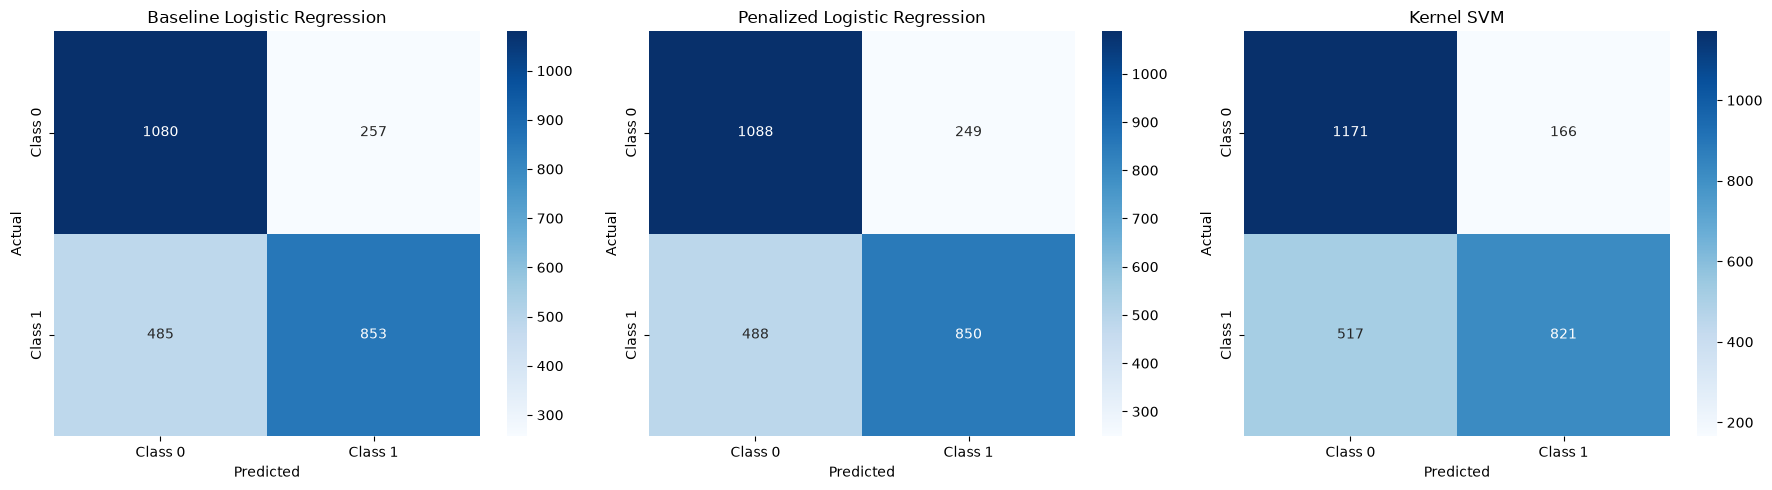

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, model_item) in zip(axes, models.items()):

    y_pred = model_item.predict(X_test)

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=ax,
        xticklabels=['Class 0', 'Class 1'],
        yticklabels=['Class 0', 'Class 1']
    )

    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

**ROC Curve Comparison**

Receiver Operating Characteristic (ROC) curves compare the true positive rate against the false positive rate across different classification thresholds.

The true positive rate measures the proportion of actual delinquency cases correctly identified, while the false positive rate measures the proportion of individuals without delinquency who are incorrectly classified as positive.

A curve closer to the upper-left corner generally indicates stronger classification performance. The Area Under the ROC Curve (ROC-AUC) summarizes the model's ability to distinguish between the two target classes, with values closer to 1 indicating better discrimination and a value of 0.5 representing random classification.

Comparing the ROC curves allows us to evaluate the discrimination performance of all three models across different thresholds.

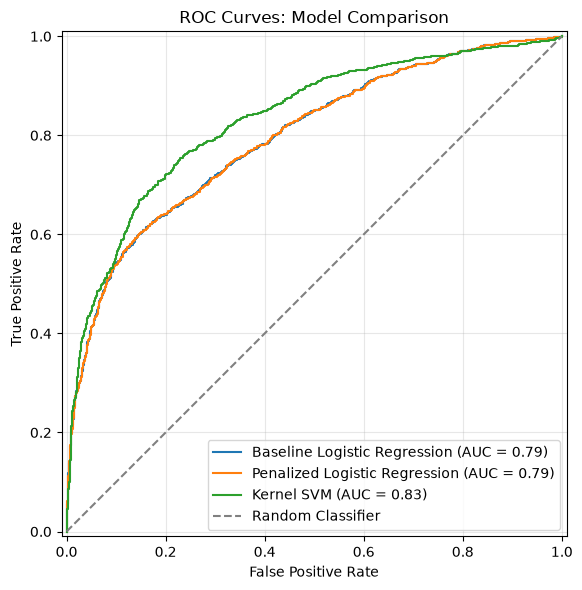

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

models = {
    'Baseline Logistic Regression': baseline_pipeline,
    'Penalized Logistic Regression': logistic_grid.best_estimator_,
    'Kernel SVM': svm_grid.best_estimator_
}

# Plot ROC curves for all three models
fig, ax = plt.subplots(figsize=(8, 6))

for name, model in models.items():
    RocCurveDisplay.from_estimator(
        model,
        X_test,
        y_test,
        name=name,
        ax=ax
    )

# Add random classifier reference line
ax.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='gray',
    label='Random Classifier'
)

ax.set_title('ROC Curves: Model Comparison')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.legend(loc='lower right')
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Precision-Recall Curve Comparison**

Precision-Recall curves illustrate the relationship between precision and recall across different classification thresholds.

Precision measures the proportion of predicted delinquency cases that were actually delinquent, while recall measures the proportion of actual delinquency cases correctly identified.

A curve closer to the upper-right corner generally indicates stronger performance. The area under the Precision-Recall curve provides an additional way to compare models, particularly when the positive and negative classes are unevenly distributed.

These curves help illustrate the tradeoff between identifying more individuals at risk of delinquency and minimizing false positive predictions.

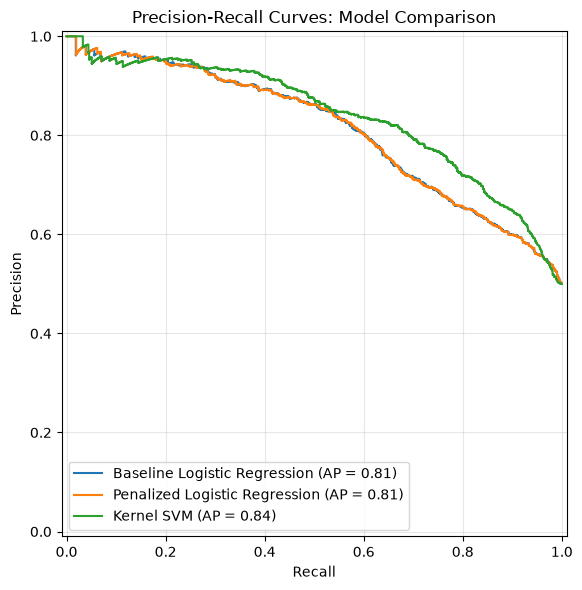

In [17]:
# Plot Precision-Recall curves for all three models
fig, ax = plt.subplots(figsize=(8, 6))

for name, model in models.items():
    PrecisionRecallDisplay.from_estimator(
        model,
        X_test,
        y_test,
        name=name,
        ax=ax
    )

ax.set_title('Precision-Recall Curves: Model Comparison')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.legend(loc='lower left')
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Model Comparison and Findings

### Model Comparison and Findings

The three models demonstrated different levels of predictive performance. The baseline Logistic Regression model achieved a cross-validation ROC-AUC of 0.7841. After applying L1 regularization and tuning the hyperparameters, the penalized Logistic Regression model achieved a nearly identical ROC-AUC of 0.7851. This suggests that regularization provided only a marginal improvement over the baseline model.

The Kernel SVM performed substantially better, achieving a cross-validation ROC-AUC of 0.8228. Its optimal hyperparameters were C = 1000, gamma = 0.01, and class_weight = 'balanced'. The SVM also demonstrated the lowest cross-validation standard deviation, indicating more consistent performance across folds.

The holdout test results supported these findings. The Kernel SVM achieved the highest accuracy (0.7447), precision (0.8318), F1 score (0.7062), ROC-AUC (0.8317), and PR-AUC (0.8393). However, it had a lower recall (0.6136) than the baseline and penalized Logistic Regression models. This indicates that the SVM was more precise when predicting positive cases but identified a smaller proportion of all actual positive cases at the default classification threshold.

Overall, the Kernel SVM was the strongest-performing model based on most evaluation metrics. The two Logistic Regression models performed similarly, suggesting that regularization did not substantially improve predictive performance for this dataset. The SVM's stronger discrimination and precision-recall performance make it the most promising of the three models, although its lower recall should be considered when selecting a classification threshold.